Text to image generation using stable diffusion and diffusers

In [ ]:
# diffusers is a hugging face page for using diffusion models from huggingface hub
!pip install diffusers transformers accelerate

In [ ]:
from diffusers import StableDiffusionPipeline
import matplotlib.pyplot as plt
import torch

In [ ]:
!pip show torch

Name: torch
Version: 2.11.0+cu130
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org
Author: 
Author-email: PyTorch Team <packages@pytorch.org>
License: BSD-3-Clause
Location: /usr/local/lib/python3.13/dist-packages
Requires: cuda-bindings, cuda-toolkit, filelock, fsspec, jinja2, networkx, nvidia-cudnn-cu13, nvidia-cusparselt-cu13, nvidia-nccl-cu13, nvidia-nvshmem-cu13, setuptools, sympy, triton, typing-extensions
Required-by: accelerate, fastai, peft, sentence-transformers, timm, torchdata, torchvision


In [ ]:
import torch

print(torch.__version__)
print(torch.cuda.is_available())

2.11.0+cu130
True


In [ ]:
model_1 = "dreamlike-art/dreamlike-diffusion-1.0"
model_2 = "stabilityai/stable-diffusion-xl-base-1.0"

pipe = StableDiffusionPipeline.from_pretrained(model_1 , torch_dtype = torch.float16 , use_safetensors = True)
pipe = pipe.to("cuda")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/511 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

In [ ]:
prompt = "A majestic lion jumping from a big stone at night"

In [ ]:
result = pipe(prompt)
image = result.images[0]

  0%|          | 0/50 [00:00<?, ?it/s]

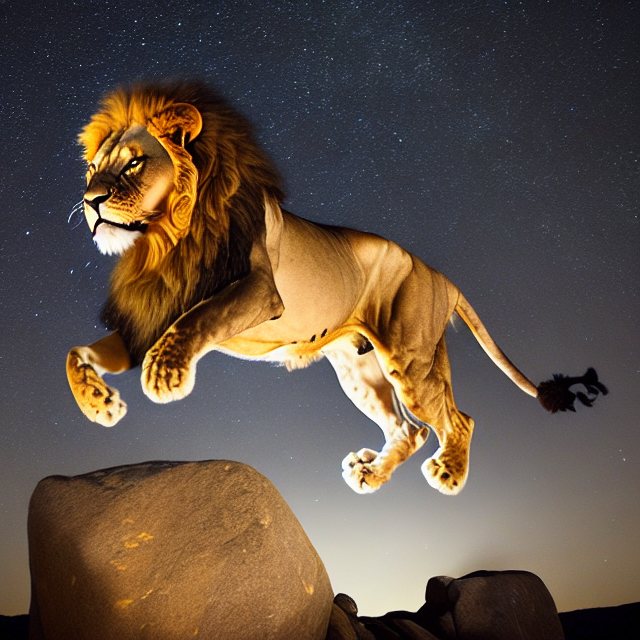

In [ ]:
image

[prompt]:  A majestic lion jumping from a big stone at night


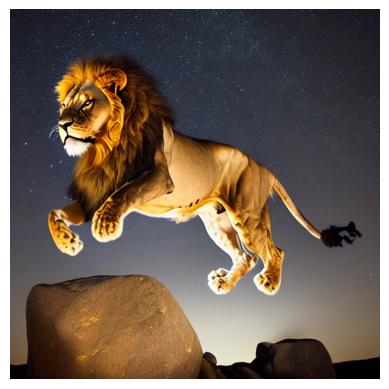

In [ ]:
print("[prompt]: " ,prompt)
plt.imshow(image);
plt.axis("off");

Working with stable diffusion parameters


-  Negative prompting
-   num_inference_steps
- height
- weight
- num_images_per_prompt



In [ ]:
def generate_image(pipe, prompt , params):
  img = pipe(prompt , **params).images

  num_images = len(img)
  if num_images>1:
    fig, ax = plt.subplots(nrows=1 , ncols = num_images)
    for i in range(num_images):
      ax[i].imshow(img[i]);
      ax[i].axis('off');

  else:
    fig = plt.figure()
    plt.imshow(img[0]);
    plt.axis('off');
  plt.tight_layout()

In [ ]:
params={}

In [ ]:
prompt = "A majestic lion jumping from a big stone at night"

  0%|          | 0/50 [00:00<?, ?it/s]

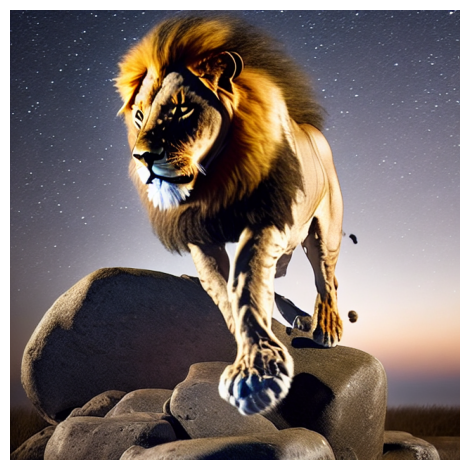

In [ ]:
generate_image(pipe , prompt , params)

  0%|          | 0/100 [00:00<?, ?it/s]

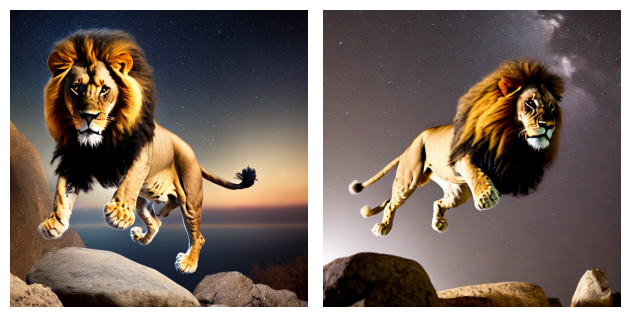

In [ ]:
# num inference steps
params= {'num_inference_steps' : 100 , 'num_images_per_prompt': 2}
generate_image(pipe , prompt , params)

In [ ]:
# height widht
params = {'num_inference_steps': 100 , 'width': 512 , 'height': int(1.5*640) , 'negative_prompt': 'ugly , distorted, low quality'}

  0%|          | 0/100 [00:00<?, ?it/s]

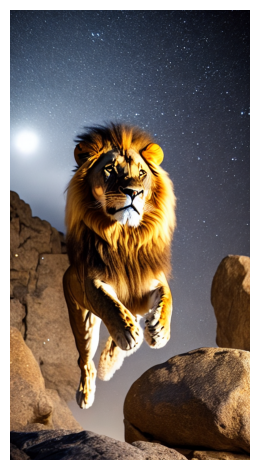

In [ ]:
generate_image(pipe , prompt, params)